# Animaciones

La nomenclatura $b_4 \dots N \dots w_4$ representa el ciclo completo de selección incremental y deconstrucción de la constelación de satélites visibles en cada época, ordenada de mayor a menor elevación. El proceso inicia en $b_4$ (best 4), donde se resuelve la posición utilizando únicamente los cuatro satélites con mayor ángulo de elevación (la mejor calidad de señal individual). A partir de allí, se añade progresivamente un satélite a la vez ($b_5, b_6, \dots$) hasta alcanzar $N$, la solución con la constelación completa observada. Posteriormente, el algoritmo comienza a retirar satélites desde los de mayor elevación hacia abajo ($w_{N-1}, w_{N-2}, \dots$), reduciendo la geometría disponible hasta finalizar en $w_4$ (worst 4), que calcula la posición empleando únicamente los cuatro satélites más bajos sobre el horizonte. Este recorrido sistemático permite evaluar cómo varía la precisión, la geometría (DOP) y la estabilidad de la solución según la elevación y el número de satélites seleccionados.


1. **Animación 1: Convergencia del método Gauss-Newton por época**

    ¿Qué hace? Evalúa la velocidad y el comportamiento del proceso iterativo de estimación de posición desde el centro de la Tierra (0,0,0) hasta la solución.

    Comportamiento visual: Cada frame representa una época (tiempo GPS). Dentro de la gráfica se dibujan simultáneamente múltiples curvas que corresponden a las distintas agrupaciones de satélites (desde los 4 con mayor elevación b4​, pasando por la constelación completa N, hasta los 4 con menor elevación w4​). La paleta de colores (cmap) permite diferenciar de forma clara si una agrupación con mejor o peor geometría necesita más o menos iteraciones para converger.

2. **Animación 2: Evolución temporal del error horizontal y vertical**

    ¿Qué hace? Analiza la dispersión de los errores de posicionamiento en las coordenadas locales Este-Norte (E,N) y la variación del error en altura (U) a lo largo de todo el día.

    Comportamiento visual: Cada frame representa una agrupación específica de satélites (b4​,…,N,…,w4​) mantenida fija mientras transcurre el día.

    En el panel izquierdo se grafican los puntos de error horizontal respecto a la posición de referencia fija en (0,0).

    En el panel derecho se muestra la serie de tiempo del error vertical (altura). El color único de cada frame (marcado en el colorbar) revela cómo la precisión se degrada o mejora al seleccionar satélites en diferentes rangos de elevación.

3. **Animación 3: Residuos del ajuste frente a la elevación de los satélites**

    ¿Qué hace? Muestra la relación entre la calidad de la medida (el residuo v tras el ajuste de mínimos cuadrados) y el ángulo de elevación de los satélites sobre el horizonte.

    Comportamiento visual: Cada frame corresponde a una agrupación de satélites. Se representan los residuos en metros de todos los satélites incluidos en dicha agrupación para las diferentes épocas. Permite visualizar claramente la tendencia física: los satélites a baja elevación (cerca de 0∘) presentan mayor dispersión y residuos más grandes debido a los efectos atmosféricos y el multicamino.

4. **Animación 4: Elipses de error de posicionamiento horizontal**

    ¿Qué hace? Representa la incertidumbre espacial y la propagación de errores en el plano horizontal a través de las matrices de covarianza (ΣENU​).

    Comportamiento visual: Cada frame representa una época. En la gráfica, la posición de referencia verdadera se sitúa fija en el origen (0,0). Se dibujan las estimaciones de posición calculadas para todas las agrupaciones de satélites con sus respectivos colores, rodeadas por sus elipses de error a 1σ, 2σ y 3σ. Las elipses tienen niveles de transparencia (alpha) progresivos para observar qué combinación de satélites acota mejor la incertidumbre de la estación.

5. **Animación 5: Evolución de los factores de dilución de la precisión (DOPs)**

    ¿Qué hace? Muestra el comportamiento continuo de la calidad geométrica de la constelación a lo largo del tiempo mediante los indicadores PDOP (3D), HDOP (Horizontal) y VDOP (Vertical).

    Comportamiento visual: Cada frame representa una agrupación de satélites. A través de tres subplots alineados temporalmente, se observa cómo cambia la geometría de los satélites seleccionados durante el día. Permite identificar momentos de degradación geométrica (picos de DOP) asociados al filtrado de satélites por elevación.

6. **Animación 6: Distribución espacial en el cielo (Proyección Polar)**

    ¿Qué hace? Visualiza la posición astrométrica (azimut y elevación) de todos los satélites GPS visibles sobre el horizonte de la estación.

    Comportamiento visual: Cada frame representa una época. Se utiliza un diagrama polar centrado en el cenit (90∘ de elevación al centro y 0∘ en el borde). Los satélites se representan mediante puntos etiquetados con su identificador (ej. G15) y coloreados con un mapa de color invertido: tonos oscuros para satélites en posiciones altas (cerca del cenit) y tonos claros para satélites cercanos al horizonte.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.dates as mdates
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Ellipse
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from tqdm import tqdm
#from tqdm.notebook import tqdm

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

## 0. Datos: la tabla de `gnss_pseudodistancia.ipynb`

In [2]:
# =============================================================================
# CONSTANTES Y PARÁMETROS
# =============================================================================
C = 299792458.0
ESTACION = "KOUR00GUF"
FECHA = "2026-09-15"
PREFIJO = f"{ESTACION[:4].lower()}_{FECHA.replace('-', '')}"
WGS84_A, WGS84_F = 6378137.0, 1/298.257223563

# Carga de datos y referencia
D = pd.read_csv(f"data/{PREFIJO}_gps.csv", parse_dates=["t"])
lineas_est = open(f"data/{PREFIJO}_estacion.txt").read().splitlines()[1:]
est_dict = dict(linea.split() for linea in lineas_est)
RX = np.array([float(est_dict["X"]), float(est_dict["Y"]), float(est_dict["Z"])])

## Solución de variables

In [3]:
# =============================================================================
# FUNCIONES BASE
# =============================================================================
def xyz_a_geodesicas(X, Y, Z, a=WGS84_A, f=WGS84_F):
    e2 = f * (2 - f)
    lon = np.arctan2(Y, X)
    p = np.hypot(X, Y)
    lat = np.arctan2(Z, p * (1 - e2))
    for _ in range(10):
        N = a / np.sqrt(1 - e2 * np.sin(lat)**2)
        h = p / np.cos(lat) - N
        lat = np.arctan2(Z, p * (1 - e2 * N / (N + h)))
    return lat, lon, h

LAT_REF, LON_REF, H_REF = xyz_a_geodesicas(*RX)
RM = np.array([
    [-np.sin(LON_REF), np.cos(LON_REF), 0],
    [-np.sin(LAT_REF)*np.cos(LON_REF), -np.sin(LAT_REF)*np.sin(LON_REF), np.cos(LAT_REF)],
    [np.cos(LAT_REF)*np.cos(LON_REF), np.cos(LAT_REF)*np.sin(LON_REF), np.sin(LAT_REF)]
])

def diseno(x, S, P):
    r = np.linalg.norm(S - x[:3], axis=1)
    A = np.hstack([-(S - x[:3]) / r[:, None], np.ones((len(P), 1))])
    return A, P - (r + x[3])

def resolver_epoca(S, P, W=None, tol=0, maxit=10):
    x = np.zeros(4)
    W = np.eye(len(P)) if W is None else W
    historial = []
    for k in range(1, maxit + 1):
        A, dP = diseno(x, S, P)
        N_mat = A.T @ W @ A
        dx = np.linalg.solve(N_mat, A.T @ W @ dP)
        x += dx
        historial.append((k, np.linalg.norm(dx[:3])))
        if np.linalg.norm(dx) < tol: break
    A, v = diseno(x, S, P)
    Q = np.linalg.inv(A.T @ W @ A)
    return x, v, Q, historial

def covarianza_enu(Q):
    T = np.block([[RM, np.zeros((3, 1))], [np.zeros((1, 3)), np.ones((1, 1))]])
    return T @ Q @ T.T

In [ ]:
# =============================================================================
# PROCESAMIENTO POR ÉPOCAS Y AGRUPACIONES
# =============================================================================
resultados = []
epocas = sorted(D.t.unique())

for t in tqdm(epocas):
    g = D[D.t == t].sort_values("el", ascending=False).reset_index(drop=True)
    n_sv = len(g)
    if n_sv < 4: continue
    
    agrupaciones = []
    # De 4 a N satélites (desde arriba)
    for i in range(4, n_sv + 1): agrupaciones.append(g.iloc[:i])
    # Quitando desde arriba hasta llegar a los 4 peores
    for i in range(1, n_sv - 3): agrupaciones.append(g.iloc[i:])
    
    for idx_agrup, sub_g in enumerate(agrupaciones):
        S = sub_g[["xs", "ys", "zs"]].values
        P = sub_g.P1.values + C * sub_g.dts.values
        
        try:
            x, v, Q, hist = resolver_epoca(S, P)
            Qenu = covarianza_enu(Q)
            q_diag = np.diag(Qenu)
            sigma0 = np.sqrt(v @ v / (len(v) - 4)) if len(v) > 4 else 0
            enu_err = RM @ (x[:3] - RX)
            
            resultados.append({
                "t": t, "agrup_idx": idx_agrup, "frac_agrup": idx_agrup / max(1, len(agrupaciones)-1),
                "E": enu_err[0], "N": enu_err[1], "U": enu_err[2],
                "sigma0": sigma0, "Sigma": (sigma0**2) * Qenu[:2, :2] if sigma0 > 0 else np.zeros((2,2)),
                "PDOP": np.sqrt(q_diag[:3].sum()), "HDOP": np.sqrt(q_diag[:2].sum()), "VDOP": np.sqrt(q_diag[2]),
                "hist": hist, "el": sub_g.el.values, "res": v, "az": sub_g.az.values, "sv": sub_g.sv.values
            })
        except np.linalg.LinAlgError: pass

df_res = pd.DataFrame(resultados)

  0%|          | 0/2880 [00:00<?, ?it/s]

  7%|▋         | 211/2880 [00:02<00:36, 73.65it/s]

In [ ]:
# Forma recomendada en versiones modernas
cmap = plt.colormaps['inferno']

max_agrup = df_res.agrup_idx.max()
N_max = df_res["el"].apply(len).max()

# --- Mapeo dinámico de etiquetas b y w ---
# Genera: b4, b5, ..., N, w(N-1), ..., w4
cbar_labels = [f"b{i}" for i in range(4, N_max)] + [f"{N_max}"] + [f"w{i}" for i in range(N_max - 1, 3, -1)]

norm = mcolors.Normalize(vmin=0, vmax=max_agrup)
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

## 7. Solución iterativa: Gauss-Newton

Procesando Animación: 289it [00:39,  7.32it/s]                         


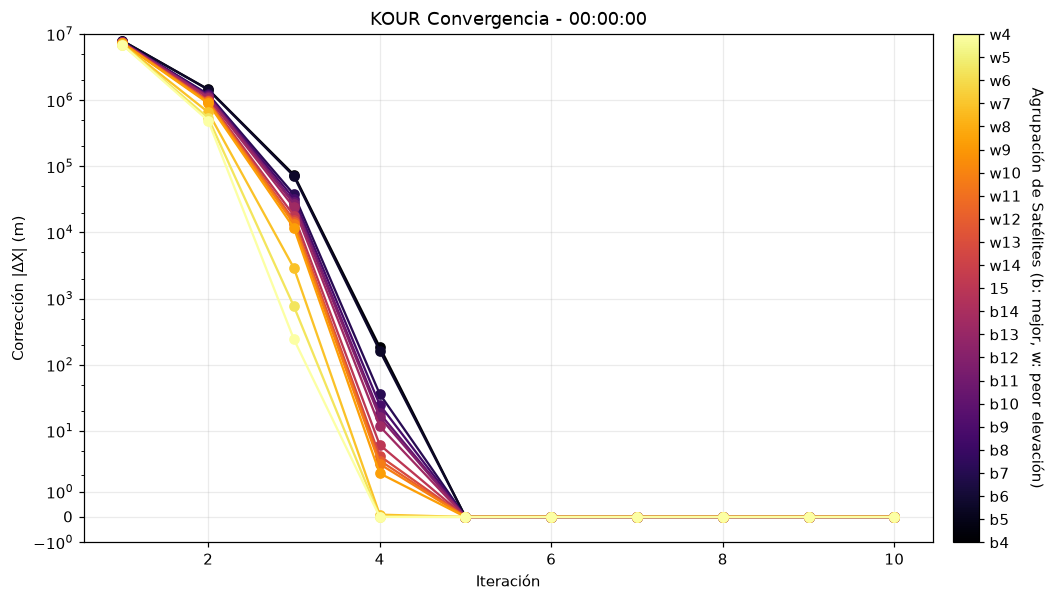

In [ ]:
# Animación 1: Convergencia por época (Frame = Época, Líneas = Agrupaciones)
fig1, ax1 = plt.subplots(figsize=(12, 6))

cbar = fig1.colorbar(sm, ax=ax1, pad=0.02)
cbar.set_label("Agrupación de Satélites (b: mejor, w: peor elevación)", rotation=270, labelpad=15)

# Asignar posiciones y etiquetas personalizadas
tick_positions = np.linspace(0, max_agrup, len(cbar_labels))
cbar.set_ticks(tick_positions)
cbar.set_ticklabels(cbar_labels)

pbar = tqdm(total=len(epocas[::10]), desc="Procesando Animación")

def update_fig1(t_val):
    ax1.clear()
    ax1.set(
        xlabel="Iteración", 
        ylabel="Corrección |ΔX| (m)", 
        yscale="asinh", 
        title=f"{ESTACION[:4]} Convergencia - {t_val.strftime('%H:%M:%S')}"
    )
    ax1.grid(True, alpha=0.25)
    ax1.set_ylim(-1, 1e7)
    
    datos_t = df_res[df_res.t == t_val]
    for _, row in datos_t.iterrows():
        iters, corrs = zip(*row["hist"])
        ax1.plot(iters, corrs, marker="o", color=cmap(row.frac_agrup))
        
    pbar.update(1)

anim1 = FuncAnimation(fig1, update_fig1, frames=epocas[::10], interval=max(int(30e3 // len(epocas[::10])), 1))
anim1.save('anim1.mp4')
pbar.close()

## 9. Solución en las 2 880 épocas: precisión, sesgo y control de calidad


Procesando Animación: 24it [00:05,  4.23it/s]                        


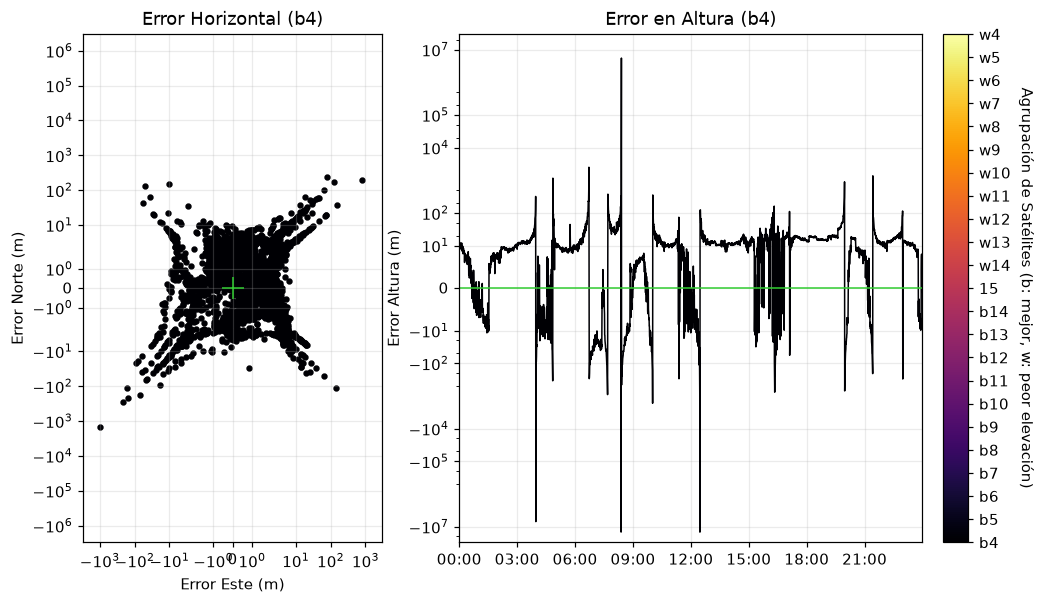

In [ ]:
# Animación 2: Error horizontal y altura (Frame = Agrupación, Puntos = Épocas)
fig2, axs2 = plt.subplots(1, 2, figsize=(12, 6), gridspec_kw={'width_ratios': [1, 1.5]})

cbar = fig1.colorbar(sm, ax=axs2, pad=0.02)
cbar.set_label("Agrupación de Satélites (b: mejor, w: peor elevación)", rotation=270, labelpad=15)

# Asignar posiciones y etiquetas personalizadas
tick_positions = np.linspace(0, max_agrup, len(cbar_labels))
cbar.set_ticks(tick_positions)
cbar.set_ticklabels(cbar_labels)

pbar = tqdm(total=(max_agrup + 1), desc="Procesando Animación")

def update_fig2(agrup_val):
    axs2[0].clear(); axs2[1].clear()
    datos_a = df_res[df_res.agrup_idx == agrup_val]
    color = cmap(agrup_val / max_agrup)
    
    # Identificador textual para el título (ej. b4, N, w4, etc.)
    idx_label = int(np.round((agrup_val / max_agrup) * (len(cbar_labels) - 1)))
    label_actual = cbar_labels[idx_label] if idx_label < len(cbar_labels) else f"Agrup {agrup_val}"
    
    # Gráfica 1: Error horizontal
    axs2[0].scatter(datos_a.E, datos_a.N, s=10, color=color)
    axs2[0].plot(0, 0, "+", color="limegreen", ms=14)
    axs2[0].set(aspect="equal", xlabel="Error Este (m)", ylabel="Error Norte (m)", 
                yscale="symlog", xscale="symlog", title=f"Error Horizontal ({label_actual})")
    axs2[0].set_ylim(-3e6, 3e6)
    axs2[0].set_xlim(-3e3, 3e3)
    axs2[0].grid(True, alpha=0.25)

    # Gráfica 2: Error en altura
    axs2[1].plot(datos_a.t, datos_a.U, color=color, lw=1)
    axs2[1].axhline(0, color="limegreen", lw=1)
    axs2[1].set(ylabel="Error Altura (m)", yscale="asinh", title=f"Error en Altura ({label_actual})")
    axs2[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    axs2[1].set_ylim(-3e7, 3e7)
    axs2[1].set_xlim(df_res.t.min(), df_res.t.max())
    axs2[1].grid(True, alpha=0.25)

    pbar.update(1)

anim2 = FuncAnimation(fig2, update_fig2, frames=range(max_agrup + 1), 
                      interval=max(int(1e4 // (max_agrup + 1)), 1000))
anim2.save('anim2.mp4')
pbar.close()

## 10. Mínimos cuadrados por elevación


Procesando Animación: 24it [00:03,  7.08it/s]                        


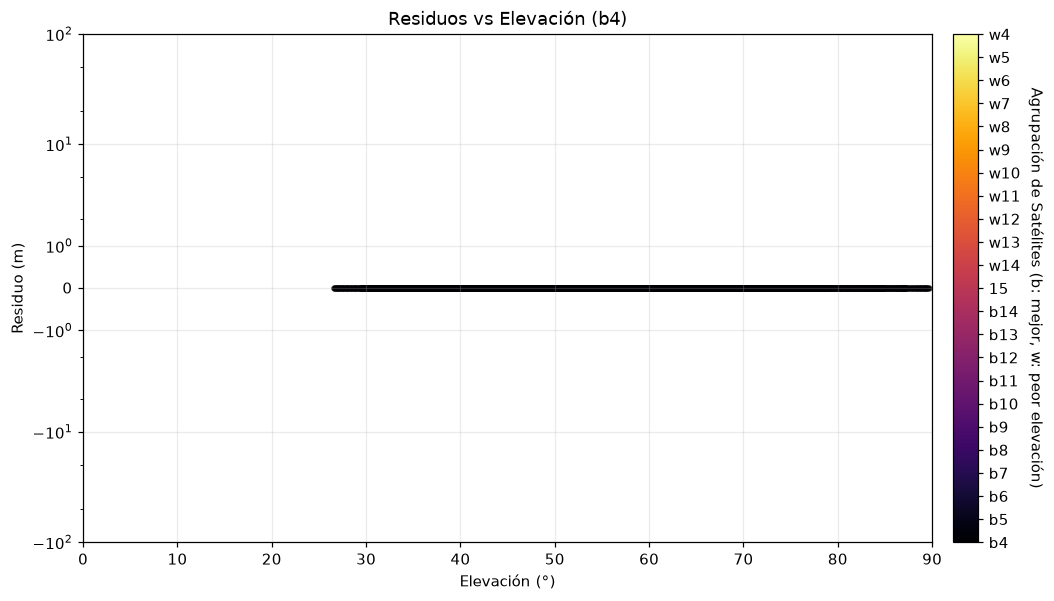

In [ ]:
# Animación 3: Residuos vs Elevación (Frame = Agrupación)
fig3, ax3 = plt.subplots(figsize=(12, 6))

cbar = fig1.colorbar(sm, ax=ax3, pad=0.02)
cbar.set_label("Agrupación de Satélites (b: mejor, w: peor elevación)", rotation=270, labelpad=15)

# Asignar posiciones y etiquetas personalizadas
tick_positions = np.linspace(0, max_agrup, len(cbar_labels))
cbar.set_ticks(tick_positions)
cbar.set_ticklabels(cbar_labels)

pbar = tqdm(total=(max_agrup + 1), desc="Procesando Animación")

def update_fig3(agrup_val):
     # Identificador textual para el título (ej. b4, N, w4, etc.)
    idx_label = int(np.round((agrup_val / max_agrup) * (len(cbar_labels) - 1)))
    label_actual = cbar_labels[idx_label] if idx_label < len(cbar_labels) else f"Agrup {agrup_val}"

    ax3.clear()
    ax3.set(xlabel="Elevación (°)", ylabel="Residuo (m)", title=f"Residuos vs Elevación ({label_actual})", ylim=(-1e2, 1e2), xlim=(0, 90), yscale="asinh")
    datos_a = df_res[df_res.agrup_idx == agrup_val]
    color = cmap(agrup_val / max_agrup)
    if not datos_a.empty:
        els, resids = np.concatenate(datos_a.el.values), np.concatenate(datos_a.res.values)
        ax3.scatter(els, resids, color=color, alpha=0.5, s=10)
    ax3.grid(True, alpha=0.25)
    pbar.update(1)
anim3 = FuncAnimation(fig3, update_fig3, frames=range(max_agrup + 1), interval=max(1e4//(max_agrup + 1),1000))
anim3.save('anim3.mp4')
pbar.close()

## 11. Propagación de la incertidumbre: covarianza de la solución

Procesando Animación:   0%|          | 0/288 [00:00<?, ?it/s]

Procesando Animación: 289it [00:47,  6.15it/s]                         


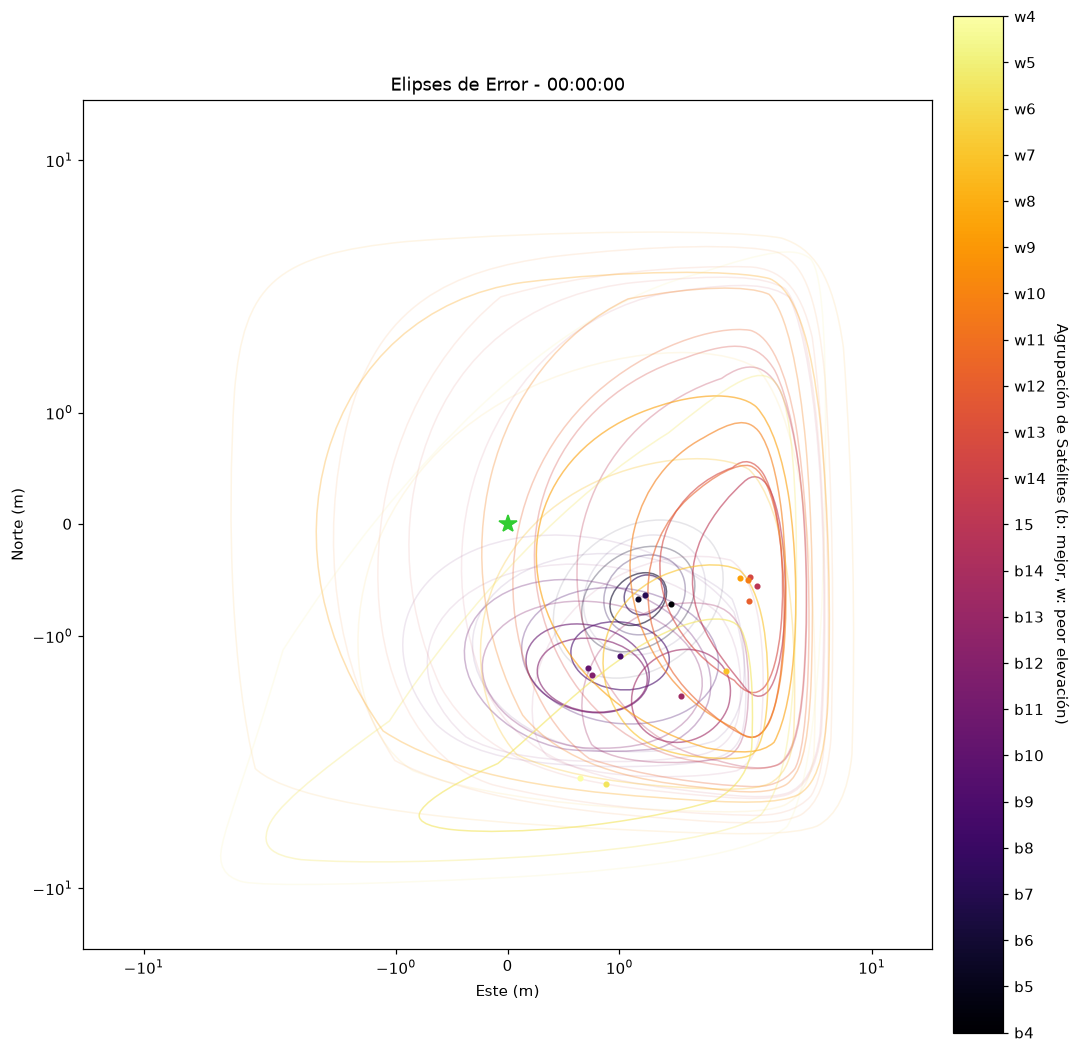

In [ ]:
# Animación 4: Elipses de error (Frame = Época, Centrado en 0,0)
fig4, ax4 = plt.subplots(figsize=(12, 12))

cbar = fig1.colorbar(sm, ax=ax4, pad=0.02)
cbar.set_label("Agrupación de Satélites (b: mejor, w: peor elevación)", rotation=270, labelpad=15)

# Asignar posiciones y etiquetas personalizadas
tick_positions = np.linspace(0, max_agrup, len(cbar_labels))
cbar.set_ticks(tick_positions)
cbar.set_ticklabels(cbar_labels)

pbar = tqdm(total=len(epocas[::10]), desc="Procesando Animación")
def update_fig4(t_val):
    ax4.clear()
    ax4.set(aspect="equal", xlabel="Este (m)", ylabel="Norte (m)", title=f"Elipses de Error - {t_val.strftime('%H:%M:%S')}", 
                xscale="symlog", yscale="symlog", ylim=(-20, 20), xlim=(-20, 20))
    ax4.plot(0, 0, "*", color="limegreen", ms=12, label="Referencia")
    datos_t = df_res[df_res.t == t_val]
    
    for _, row in datos_t.iterrows():
        c = cmap(row.frac_agrup)
        ax4.plot(row.E, row.N, ".", color=c)
        if np.sum(row.Sigma) > 0:
            val, vec = np.linalg.eigh(row.Sigma)
            ang = np.degrees(np.arctan2(vec[1, 1], vec[0, 1]))
            for k, alpha in zip([1, 2, 3], [0.6, 0.3, 0.1]):
                ax4.add_patch(Ellipse((row.E, row.N), 2*k*np.sqrt(val[1]), 2*k*np.sqrt(val[0]), 
                                      angle=ang, fill=False, ec=c, alpha=alpha))
    pbar.update(1)
anim4 = FuncAnimation(fig4, update_fig4, frames=epocas[::10], interval=max(30e3//len(epocas[::10]),1))
anim4.save('anim4.mp4')
pbar.close()

## 12. Dilución de la precisión (DOP)

Procesando Animación DOPs:   0%|          | 0/23 [00:00<?, ?it/s]

Procesando Animación DOPs: 24it [00:04,  5.90it/s]                        


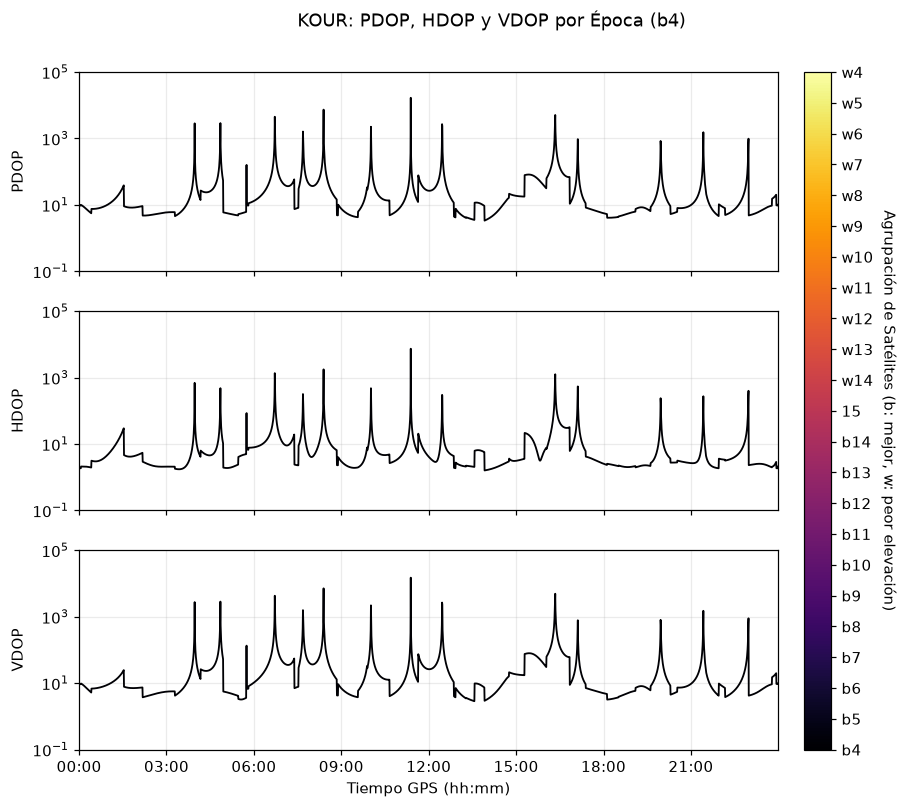

In [ ]:
# Animación 5: DOPs por Época (Frame = Agrupación)
fig5, axs5 = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
max_agrup = df_res.agrup_idx.max()

cbar5 = fig5.colorbar(sm, ax=axs5, pad=0.03, aspect=25)
cbar5.set_label("Agrupación de Satélites (b: mejor, w: peor elevación)", rotation=270, labelpad=15)

tick_positions = np.linspace(0, max_agrup, len(cbar_labels))
cbar5.set_ticks(tick_positions)
cbar5.set_ticklabels(cbar_labels)
# -----------------------------------------------------------------

pbar = tqdm(total=(max_agrup + 1), desc="Procesando Animación DOPs")

def update_fig5(agrup_val):
    # Identificador textual para el título (ej. b4, N, w4, etc.)
    idx_label = int(np.round((agrup_val / max_agrup) * (len(cbar_labels) - 1)))
    label_actual = cbar_labels[idx_label] if idx_label < len(cbar_labels) else f"Agrup {agrup_val}"

    # Limpiar los 3 ejes en cada frame
    for ax in axs5:
        ax.clear()

    datos_a = df_res[df_res.agrup_idx == agrup_val]
    color = cmap(agrup_val / max_agrup)

    if not datos_a.empty:
        axs5[0].plot(datos_a.t, datos_a.PDOP, color=color, lw=1.2)
        axs5[1].plot(datos_a.t, datos_a.HDOP, color=color, lw=1.2)
        axs5[2].plot(datos_a.t, datos_a.VDOP, color=color, lw=1.2)

    # Configuración de etiquetas y formato
    axs5[0].set_ylabel("PDOP")
    axs5[1].set_ylabel("HDOP")
    axs5[2].set_ylabel("VDOP")
    axs5[2].set_xlabel("Tiempo GPS (hh:mm)")
    axs5[2].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

    for ax in axs5:
        ax.grid(True, alpha=0.25)
        # Límites ajustados opcionales para estabilidad visual en todos los frames
        ax.set_ylim(1e-1, 1e5)
        ax.set_yscale("log")
        ax.set_xlim(df_res.t.min(), df_res.t.max())

    fig5.suptitle(f"{ESTACION[:4]}: PDOP, HDOP y VDOP por Época ({label_actual})", y=0.95)
    pbar.update(1)

anim5 = FuncAnimation(
    fig5, 
    update_fig5, 
    frames=range(max_agrup + 1), 
    interval=max(int(1e4 // (max_agrup + 1)), 1000)
)
anim5.save('anim5.mp4')
pbar.close()

Procesando Animación Polar: 289it [00:28, 10.18it/s]                         


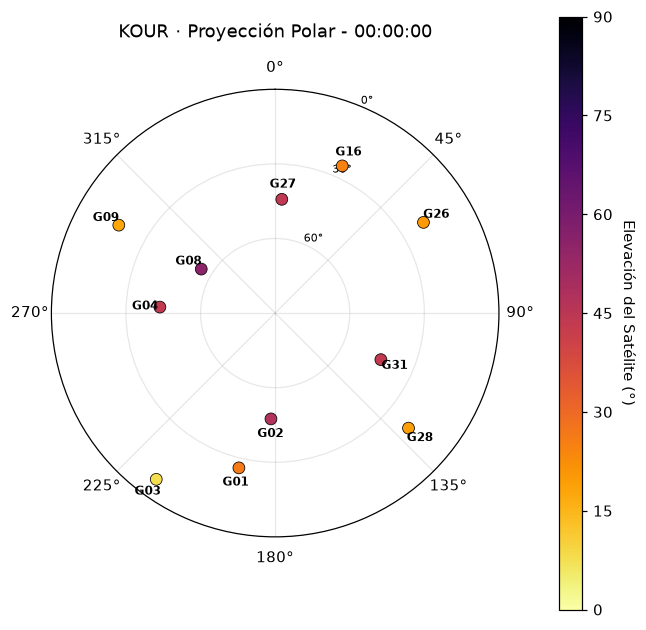

In [ ]:
# Animación 6: Proyección polar (Frame = Época)

cmap_inv = cmap.reversed()  # Invierte la escala: claros -> menor elevación, oscuros -> mayor elevación

norm_el = mcolors.Normalize(vmin=0, vmax=90)
sm_el = cm.ScalarMappable(cmap=cmap_inv, norm=norm_el)
sm_el.set_array([])

fig6, ax6 = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})

cbar6 = fig6.colorbar(sm_el, ax=ax6, pad=0.1, aspect=25)
cbar6.set_label("Elevación del Satélite (°)", rotation=270, labelpad=15)
cbar6.set_ticks(range(0, 91, 15))
# -------------------------------------------------------------------

pbar6 = tqdm(total=len(epocas[::10]), desc="Procesando Animación Polar")

def update_fig6(t_val):
    ax6.clear()
    ax6.set_theta_zero_location("N")
    ax6.set_theta_direction(-1)
    ax6.set_rlim(0, 90)
    ax6.set_yticks([0, 30, 60, 90])
    ax6.set_yticklabels(["90°", "60°", "30°", "0°"], fontsize=7)
    ax6.set_title(f"{ESTACION[:4]} · Proyección Polar - {t_val.strftime('%H:%M:%S')}", pad=15)
    ax6.grid(True, alpha=0.3)
    
    datos_t = D[D.t == t_val].sort_values("el", ascending=False)
    
    if not datos_t.empty:
        # Colorear los satélites con la paleta invertida (cmap_inv)
        colores_sat = cmap_inv(norm_el(datos_t.el.values))
        ax6.scatter(np.radians(datos_t.az), 90 - datos_t.el, color=colores_sat, s=60, edgecolors=colores_sat, linewidth=0.5, zorder=3)
        
        for _, row in datos_t.iterrows():
            ax6.text(np.radians(row.az), 90 - row.el + 6, row.sv, ha="center", va="center", fontsize=8, fontweight="bold")
            
    pbar6.update(1)

anim6 = FuncAnimation(
    fig6, 
    update_fig6, 
    frames=epocas[::10], 
    interval=max(int(30e3 // len(epocas[::10])), 1)
)
anim6.save('anim6.mp4')
pbar6.close()